(sec-7-2)=
# 7.2 Power Spectral Density and the Wiener–Khinchin Theorem

Ask a cardiologist what the noise on an ambulatory ECG looks like and you will hear words like "slow wander," "fuzz," or "spiky": descriptions of *frequency content*. Baseline wander from breathing sits below 1 Hz, electrode-motion artifacts overlap the P and T waves, and muscle tremor spreads into the band of the QRS complex. An engineer choosing a filter needs those descriptions in numbers: how much noise power is there between 0.5 and 40 Hz, and how much will survive a given filter? For a deterministic waveform the Fourier transform answers such questions. For noise it fails, because noise is a random process and each realization is different.

The answer is the **power spectral density** (PSD), which describes how the *average power* of a random process is distributed over frequency. In this section I define it carefully, derive the Wiener–Khinchin theorem that links it to the autocorrelation function of [Section 7.1](01_random_processes.ipynb), prove its basic properties, and derive the rule $S_y = |H|^2 S_x$ for a random signal passing through a filter. Two closed-form spectra, white noise and the AR(1) process, serve as test cases, and we check the theory numerically by averaging over many realizations. The section ends with real noise recorded from ECG electrodes, where the PSD tells us how much of each kind of noise a standard ECG band-pass filter can remove, and how much it cannot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-7-2-1)=
## 7.2.1 Why a Random Signal Has No Ordinary Fourier Transform

The DTFT of a sequence, $X(e^{j\Omega}) = \sum_n x[n]e^{-j\Omega n}$ from Section 10.1, converges when the sequence is absolutely summable, or at least has finite energy. A realization of a stationary random process has neither property. Its statistics do not change with time, so it does not decay: noise recorded in the 30th minute is as large as noise recorded in the first. The energy $\sum_n x^2[n]$ grows in proportion to the length of the record and is infinite for the whole realization.

We can see the consequence numerically. Take $N$ samples of white Gaussian noise with variance $\sigma^2 = 1$, compute the DFT, and look at $|X[k]|^2$. Each DFT coefficient is a sum of $N$ random terms, so its squared magnitude has expected value $N\sigma^2$: it grows without limit as we record longer. Dividing by $N$ removes the growth.

In [2]:
for N in [256, 1024, 4096, 16384]:
    x = rng.normal(0, 1.0, N)
    X2 = np.abs(np.fft.rfft(x)[1:-1]) ** 2           # exclude DC and Nyquist
    print(f"N = {N:5d}: mean |X[k]|^2 = {X2.mean():8.1f}   mean |X[k]|^2 / N = {X2.mean() / N:5.3f}")

N =   256: mean |X[k]|^2 =    227.2   mean |X[k]|^2 / N = 0.887
N =  1024: mean |X[k]|^2 =   1018.2   mean |X[k]|^2 / N = 0.994
N =  4096: mean |X[k]|^2 =   4132.5   mean |X[k]|^2 / N = 1.009
N = 16384: mean |X[k]|^2 =  16594.3   mean |X[k]|^2 / N = 1.013


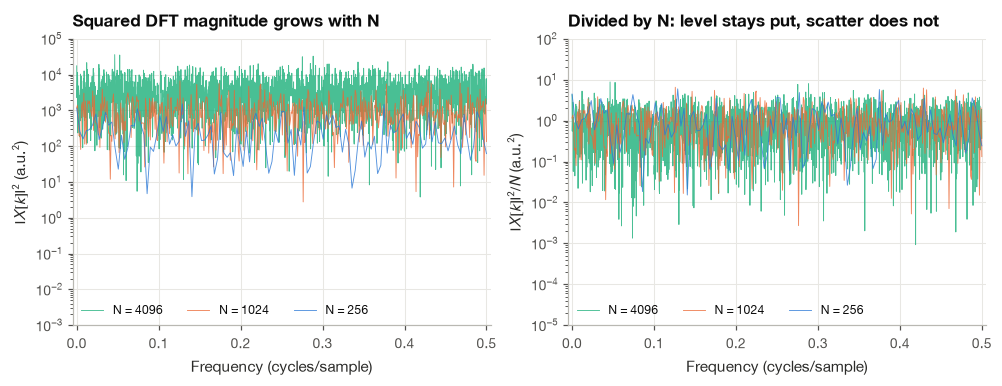

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for i, N in reversed(list(enumerate([256, 1024, 4096]))):
    x = rng.normal(0, 1.0, N)
    X2 = np.abs(np.fft.rfft(x)) ** 2
    f_norm = np.fft.rfftfreq(N)
    axes[0].semilogy(f_norm, X2, color=C[i], lw=0.6, alpha=0.8, label=f"N = {N}")
    axes[1].semilogy(f_norm, X2 / N, color=C[i], lw=0.6, alpha=0.8, label=f"N = {N}")
axes[0].set(xlabel="Frequency (cycles/sample)", ylabel=r"$|X[k]|^2$ (a.u.$^2$)",
            title="Squared DFT magnitude grows with N", ylim=(1e-3, 1e5))
axes[1].set(xlabel="Frequency (cycles/sample)", ylabel=r"$|X[k]|^2 / N$ (a.u.$^2$)",
            title="Divided by N: level stays put, scatter does not", ylim=(1e-5, 1e2))
for ax in axes:
    ax.legend(loc="lower left", ncols=3, fontsize=8)
plt.show()

The right panel contains two lessons. Dividing by $N$ produces a quantity whose *level* no longer depends on the record length, which is the hint we follow in the next subsection. But the scatter around that level does not shrink as $N$ grows: a longer record gives more frequency points, each as erratic as before. To get a well-defined spectrum we also need an *expectation*. (The persistent scatter is the central difficulty of practical spectral estimation and the subject of [Section 7.3](03_nonparametric_psd.ipynb).)

(sec-7-2-2)=
## 7.2.2 Defining the Power Spectral Density

Let $x[n]$ be a WSS process and let $X_N(e^{j\Omega})$ be the DTFT of its first $N$ samples,

$$
X_N(e^{j\Omega}) = \sum_{n=0}^{N-1} x[n]\,e^{-j\Omega n}.
$$

This finite sum always exists. Following the hint above, we divide its squared magnitude by $N$, average over the ensemble, and let the record grow:

(eq-7-12)=
\begin{equation*}
S_x(e^{j\Omega}) = \lim_{N \to \infty} \frac{1}{N}\,\mathbb{E}\left\{\big|X_N(e^{j\Omega})\big|^2\right\}. \tag{7.12}
\end{equation*}

This is the **power spectral density**. Each ingredient has a job. Truncation to $N$ samples makes the Fourier transform exist. Division by $N$ converts energy into power (energy per sample). The expectation removes the realization-to-realization scatter. The limit removes the dependence on the particular record length.

For a continuous-time process the definition is the same with integrals in place of sums: truncate to $0 \le t \le T$, compute $X_T(f) = \int_0^T x(t)e^{-j2\pi f t}\,dt$, and set $S_x(f) = \lim_{T\to\infty} \mathbb{E}\{|X_T(f)|^2\}/T$. Everything below carries over line by line.

(sec-7-2-3)=
## 7.2.3 The Wiener–Khinchin Theorem

Definition [(7.12)](#eq-7-12) is conceptually clear but awkward to compute, because it involves a limit of expectations of squared Fourier transforms. The **Wiener–Khinchin theorem** {cite:p}`wiener1930,khintchine1934` replaces it with a single Fourier transform of the autocorrelation function. The derivation uses the same lag-counting trick we used for ergodicity in equation [(7.6)](01_random_processes.ipynb#eq-7-6).

**Step 1: write the squared magnitude as a double sum.** Since $x[n]$ is real, $|X_N|^2 = X_N X_N^*$, and the conjugate flips the sign of the exponent:

$$
\big|X_N(e^{j\Omega})\big|^2 = \sum_{n=0}^{N-1} x[n]e^{-j\Omega n}\;\sum_{m=0}^{N-1} x[m]e^{+j\Omega m}
= \sum_{n=0}^{N-1}\sum_{m=0}^{N-1} x[n]\,x[m]\,e^{-j\Omega (n - m)}.
$$

**Step 2: take the expectation.** Expectation is linear and the exponentials are not random, so it moves inside the sums and acts only on the product $x[n]x[m]$. By wide-sense stationarity, $\mathbb{E}\{x[n]x[m]\} = R_x[n - m]$:

$$
\mathbb{E}\left\{\big|X_N(e^{j\Omega})\big|^2\right\} = \sum_{n=0}^{N-1}\sum_{m=0}^{N-1} R_x[n-m]\,e^{-j\Omega (n-m)}.
$$

**Step 3: group the terms by lag.** The summand depends on $n$ and $m$ only through $k = n - m$, which ranges from $-(N-1)$ to $N-1$. As in [Section 7.1.4](01_random_processes.ipynb#sec-7-1-4), lag $k$ occurs on exactly $N - |k|$ of the $N^2$ index pairs, so

(eq-7-13)=
\begin{equation*}
\frac{1}{N}\,\mathbb{E}\left\{\big|X_N(e^{j\Omega})\big|^2\right\} = \sum_{k=-(N-1)}^{N-1}\left(1 - \frac{|k|}{N}\right) R_x[k]\,e^{-j\Omega k}. \tag{7.13}
\end{equation*}

**Step 4: let $N$ grow.** For every fixed $k$ the weight $1 - |k|/N$ tends to one. If the autocorrelation is absolutely summable, $\sum_k |R_x[k]| < \infty$, the terms with large $|k|$ contribute negligibly and the limit may be taken term by term. The result is

(eq-7-14)=
\begin{equation*}
\boxed{\,S_x(e^{j\Omega}) = \sum_{k=-\infty}^{\infty} R_x[k]\,e^{-j\Omega k}\,} \tag{7.14}
\end{equation*}

The power spectral density is the DTFT of the autocorrelation function. The inverse DTFT gives the autocorrelation back,

(eq-7-15)=
\begin{equation*}
R_x[k] = \frac{1}{2\pi}\int_{-\pi}^{\pi} S_x(e^{j\Omega})\,e^{j\Omega k}\,d\Omega , \tag{7.15}
\end{equation*}

so $R_x$ and $S_x$ carry exactly the same information, once in the lag domain and once in the frequency domain. In continuous time the pair reads $S_x(f) = \int R_x(\tau)e^{-j2\pi f\tau}\,d\tau$.

Equation [(7.13)](#eq-7-13) deserves a second look before we move on, because it is exact for finite $N$. It says that the expected value of $|X_N|^2/N$ is the Fourier transform of the true autocorrelation multiplied by a triangle of width $2N$. Multiplication by a triangle in the lag domain means smoothing in the frequency domain, so at finite $N$ the expected spectrum is a blurred version of $S_x$. This is the origin of the bias of the periodogram, which we quantify in [Section 7.3](03_nonparametric_psd.ipynb). We can check [(7.13)](#eq-7-13) and its limit [(7.14)](#eq-7-14) numerically with the AR(1) process of [Section 7.1](01_random_processes.ipynb#sec-7-1), whose autocorrelation $R_x[k] = \sigma_w^2 a^{|k|}/(1 - a^2)$ we derived in equation [(7.9)](01_random_processes.ipynb#eq-7-9). For a short record of $N = 16$ samples the blurring is visible.

In [4]:
a, sigma_w, N = 0.9, 1.0, 16
R = lambda k: sigma_w**2 / (1 - a**2) * a ** np.abs(k)
Omegas = np.array([0, np.pi / 16, np.pi / 4, np.pi / 2, np.pi])

# Monte Carlo: 40,000 AR(1) records of length N (burn-in removed), DTFT at each Omega
w = rng.normal(0, sigma_w, size=(40_000, N + 300))
x = signal.lfilter([1.0], [1.0, -a], w, axis=1)[:, 300:]
E = np.exp(-1j * np.outer(np.arange(N), Omegas))
mc = np.mean(np.abs(x @ E) ** 2, axis=0) / N

k = np.arange(-(N - 1), N)
finite = np.array([np.sum((1 - np.abs(k) / N) * R(k) * np.exp(-1j * W * k)).real for W in Omegas])
k_long = np.arange(-3000, 3001)
limit = np.array([np.sum(R(k_long) * np.exp(-1j * W * k_long)).real for W in Omegas])

table = pd.DataFrame({"Omega (rad)": Omegas, "Monte Carlo E|X_N|^2/N": mc,
                      "Equation (12.13), N=16": finite, "Equation (12.14), N->inf": limit})
print(table.round(3).to_string(index=False))

 Omega (rad)  Monte Carlo E|X_N|^2/N  Equation (12.13), N=16  Equation (12.14), N->inf
       0.000                  51.895                  51.761                   100.000
       0.196                  31.241                  31.176                    22.428
       0.785                   2.728                   2.731                     1.861
       1.571                   0.819                   0.818                     0.552
       3.142                   0.412                   0.411                     0.277


The Monte Carlo average agrees with the finite-$N$ formula [(7.13)](#eq-7-13) to within its sampling error at every frequency, and both differ visibly from the limit [(7.14)](#eq-7-14): the peak at $\Omega = 0$ is lowered from 100 to about 52 and the floor at $\Omega = \pi$ is raised, exactly the blurring described above.

**Example 7.2.1.** Find the PSD of the AR(1) process in closed form.

We insert $R_x[k] = \sigma_x^2 a^{|k|}$, with $\sigma_x^2 = \sigma_w^2/(1 - a^2)$, into [(7.14)](#eq-7-14) and split the sum into non-negative and negative lags.

**Step 1: split the sum.** Writing negative lags as $k = -m$ with $m \ge 1$,

$$
\frac{S_x(e^{j\Omega})}{\sigma_x^2} = \sum_{k=0}^{\infty} \big(a e^{-j\Omega}\big)^k + \sum_{m=1}^{\infty} \big(a e^{j\Omega}\big)^m .
$$

**Step 2: sum the geometric series.** Both ratios have magnitude $|a| < 1$, so $\sum_{k\ge 0} q^k = 1/(1-q)$ and $\sum_{m \ge 1} q^m = q/(1 - q)$:

$$
\frac{S_x(e^{j\Omega})}{\sigma_x^2} = \frac{1}{1 - a e^{-j\Omega}} + \frac{a e^{j\Omega}}{1 - a e^{j\Omega}} .
$$

**Step 3: combine over a common denominator.** The product of the denominators is $(1 - ae^{-j\Omega})(1 - ae^{j\Omega}) = 1 - a(e^{j\Omega} + e^{-j\Omega}) + a^2 = 1 - 2a\cos\Omega + a^2$, by equation (2.2). The numerator is $(1 - ae^{j\Omega}) + ae^{j\Omega}(1 - ae^{-j\Omega}) = 1 - a^2$. Therefore

(eq-7-16)=
\begin{equation*}
S_x(e^{j\Omega}) = \sigma_x^2\,\frac{1 - a^2}{1 - 2a\cos\Omega + a^2} = \frac{\sigma_w^2}{1 - 2a\cos\Omega + a^2}. \tag{7.16}
\end{equation*}

At $\Omega = 0$ with $a = 0.9$ this gives $1/(1 - 1.8 + 0.81) = 1/0.01 = 100$, and at $\Omega = \pi$ it gives $1/(1 + 0.9)^2 \approx 0.277$, matching the last column of the table. For $a > 0$ the denominator is smallest at $\Omega = 0$, so the power is concentrated at low frequencies: a slowly decaying autocorrelation means a low-pass spectrum. For $a < 0$ the autocorrelation alternates in sign and the power moves to high frequencies. The figure shows both cases as Wiener–Khinchin pairs.

In [5]:
def ar1_psd(Omega, a, sigma_w=1.0):
    """Closed-form PSD of an AR(1) process, equation (12.16)."""
    return sigma_w**2 / (1 - 2 * a * np.cos(Omega) + a**2)


print(f"Max |closed form - truncated series| at the table frequencies: "
      f"{np.max(np.abs(ar1_psd(Omegas, a) - limit)):.1e}")

Max |closed form - truncated series| at the table frequencies: 1.4e-13


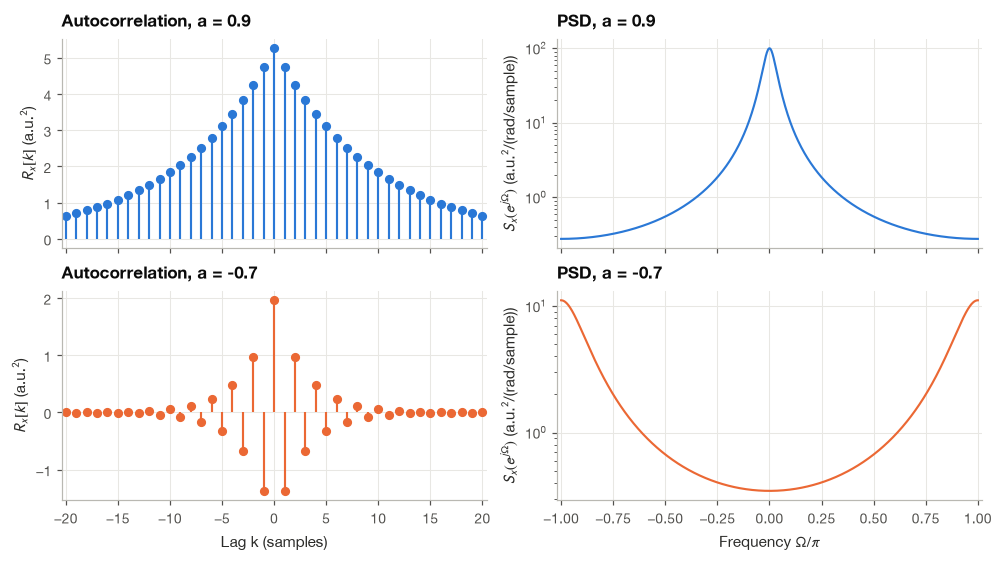

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.0), sharex="col")
lags = np.arange(-20, 21)
W = np.linspace(-np.pi, np.pi, 801)
for row, (a_i, col) in enumerate([(0.9, C[0]), (-0.7, C[1])]):
    R_i = a_i ** np.abs(lags) / (1 - a_i**2)
    axes[row, 0].stem(lags, R_i, linefmt=col, markerfmt="o", basefmt=" ")
    axes[row, 0].set(ylabel="$R_x[k]$ (a.u.$^2$)", title=f"Autocorrelation, a = {a_i}")
    axes[row, 1].plot(W / np.pi, ar1_psd(W, a_i), color=col)
    axes[row, 1].set(ylabel=r"$S_x(e^{j\Omega})$ (a.u.$^2$/(rad/sample))", yscale="log",
                     title=f"PSD, a = {a_i}")
axes[1, 0].set_xlabel("Lag k (samples)")
axes[1, 1].set_xlabel(r"Frequency $\Omega/\pi$")
plt.show()

(sec-7-2-4)=
## 7.2.4 Properties of the Power Spectral Density

Four properties follow directly from the definition [(7.12)](#eq-7-12) and the theorem [(7.14)](#eq-7-14). They hold for every WSS process and are useful sanity checks on any estimated spectrum.

**Real.** Pair the terms $k$ and $-k$ in [(7.14)](#eq-7-14) and use the even symmetry $R_x[-k] = R_x[k]$ from [Section 7.1.3](01_random_processes.ipynb#sec-7-1-3):

$$
S_x(e^{j\Omega}) = R_x[0] + \sum_{k=1}^{\infty} R_x[k]\big(e^{-j\Omega k} + e^{j\Omega k}\big) = R_x[0] + 2\sum_{k=1}^{\infty} R_x[k]\cos(\Omega k).
$$

Every term is real, so the PSD is real. It contains no phase information at all: two signals that differ only in the timing of their components have the same PSD.

**Even.** The cosine expansion is unchanged when $\Omega$ is replaced by $-\Omega$, so $S_x(e^{-j\Omega}) = S_x(e^{j\Omega})$. As with the amplitude spectrum of any real signal, the negative frequencies mirror the positive ones.

**Non-negative.** By [(7.12)](#eq-7-12), $S_x$ is a limit of averages of squared magnitudes divided by positive numbers, and none of those can be negative. (This is far from obvious from the cosine expansion alone, and it is the reason an autocorrelation estimate must be positive semidefinite to yield a valid spectrum.)

**Area equals power.** Setting $k = 0$ in the inverse relation [(7.15)](#eq-7-15) gives

(eq-7-17)=
\begin{equation*}
R_x[0] = \mathbb{E}\{x^2[n]\} = \frac{1}{2\pi}\int_{-\pi}^{\pi} S_x(e^{j\Omega})\,d\Omega. \tag{7.17}
\end{equation*}

The total area under the PSD, suitably normalized, is the mean power of the process. This is what justifies the word *density*: $S_x$ is power per unit frequency, and the power in any band is the area of the PSD over that band.

### From radians per sample to hertz, and from two-sided to one-sided

Physiological spectra are plotted in hertz, not in radians per sample. With $\Omega = 2\pi f/f_s$ we have $d\Omega = 2\pi\,df/f_s$, and the interval $-\pi \le \Omega \le \pi$ maps to $-f_s/2 \le f \le f_s/2$. Substituting into [(7.17)](#eq-7-17),

$$
R_x[0] = \frac{1}{2\pi}\int_{-f_s/2}^{f_s/2} S_x\big(e^{j2\pi f/f_s}\big)\,\frac{2\pi}{f_s}\,df = \int_{-f_s/2}^{f_s/2} \underbrace{\frac{1}{f_s}S_x\big(e^{j2\pi f/f_s}\big)}_{S_x(f)}\,df .
$$

So the PSD *per hertz* is $S_x(f) = S_x(e^{j2\pi f/f_s})/f_s$, and its integral over frequency in hertz is the power. If the signal is in µV, as for EEG, $S_x(f)$ is in **µV²/Hz**; for ECG in mV it is in mV²/Hz.

Because the PSD of a real signal is even, it is common to fold the negative frequencies onto the positive ones and report the **one-sided** PSD

(eq-7-18)=
\begin{equation*}
S_x^{(1)}(f) = 2\,S_x(f), \qquad 0 < f < f_s/2, \tag{7.18}
\end{equation*}

with the values at $f = 0$ and $f = f_s/2$ left undoubled, since those frequencies are their own mirror images. Then $\int_0^{f_s/2} S_x^{(1)}(f)\,df = R_x[0]$ and the power in a band $f_1 \le f \le f_2$ is $\int_{f_1}^{f_2} S_x^{(1)}(f)\,df$. Physiological software (including `scipy.signal.welch` with its default settings) reports one-sided densities. I recommend always stating which convention a plot uses; a factor of two in power is a 3 dB discrepancy, enough to confuse a comparison between studies.

We now check [(7.17)](#eq-7-17) for the AR(1) process: the area under [(7.16)](#eq-7-16), divided by $2\pi$, should equal $\sigma_x^2 = \sigma_w^2/(1 - a^2) = 5.263$ for $a = 0.9$. We then repeat the check in hertz with $f_s = 360$ Hz.

In [7]:
W = np.linspace(-np.pi, np.pi, 200_001)
area_rad = np.trapezoid(ar1_psd(W, a), W) / (2 * np.pi)

fs = 360.0
f = np.linspace(0, fs / 2, 100_001)
S_onesided = 2 * ar1_psd(2 * np.pi * f / fs, a) / fs          # equation (12.18), per Hz
area_hz = np.trapezoid(S_onesided, f)
print(f"Area / 2pi over [-pi, pi]       : {area_rad:.4f}")
print(f"Area of one-sided PSD in Hz     : {area_hz:.4f}")
print(f"Variance sigma_w^2 / (1 - a^2)  : {sigma_w**2 / (1 - a**2):.4f}")

Area / 2pi over [-pi, pi]       : 5.2632
Area of one-sided PSD in Hz     : 5.2632
Variance sigma_w^2 / (1 - a^2)  : 5.2632


(sec-7-2-5)=
## 7.2.5 White Noise

White noise has $R_w[k] = \sigma_w^2\,\delta[k]$, equation [(7.7)](01_random_processes.ipynb#eq-7-7). Only one term survives in the Wiener–Khinchin sum [(7.14)](#eq-7-14):

(eq-7-19)=
\begin{equation*}
S_w(e^{j\Omega}) = \sum_k \sigma_w^2\,\delta[k]\,e^{-j\Omega k} = \sigma_w^2 \quad \text{for all } \Omega. \tag{7.19}
\end{equation*}

The PSD is flat: every frequency carries the same power density, which is the reason for the name. In hertz, the two-sided density is $\sigma_w^2/f_s$ and the one-sided density is $2\sigma_w^2/f_s$, spread over $0$ to $f_s/2$.

**Example 7.2.2.** An ECG front end adds white noise with an RMS value of 5 µV, and the signal is sampled at $f_s = 500$ Hz. What is the one-sided noise PSD, and how much noise power falls in the 0.5–40 Hz monitoring band?

The variance is $\sigma_w^2 = 25$ µV². The one-sided PSD is $2 \times 25/500 = 0.1$ µV²/Hz, constant from 0 to 250 Hz (amplifier data sheets often quote its square root, $0.32\ \mu\text{V}/\sqrt{\text{Hz}}$). The power in the band is the area $0.1 \times (40 - 0.5) = 3.95$ µV², an RMS value of about 2.0 µV. Narrowing the band reduces white noise in proportion to the bandwidth, which is one quantitative reason monitoring filters are narrower than diagnostic ones.

A subtle point: in continuous time, perfectly white noise would have a flat PSD over *all* frequencies and therefore infinite power, by [(7.17)](#eq-7-17). Physical noise is white only over a limited band, beyond which the amplifier's own frequency response rolls it off. In discrete time the problem disappears because the frequency axis ends at $f_s/2$.

(sec-7-2-6)=
## 7.2.6 Random Signals Through LTI Systems

When a random signal passes through a filter, we cannot predict the output samples, but we can predict the output PSD. Let $y[n] = \sum_i h[i]\,x[n-i]$, with $h$ real and stable and $x$ WSS.

**Step 1: the output autocorrelation.** Substituting the convolution sum twice, once for $y[n]$ with summation index $i$ and once for $y[n+k]$ with index $l$, and moving the expectation inside,

$$
\begin{aligned}
R_y[k] = \mathbb{E}\{y[n]\,y[n+k]\}
&= \mathbb{E}\Big\{\sum_i h[i]\,x[n-i]\;\sum_l h[l]\,x[n+k-l]\Big\} \\
&= \sum_i\sum_l h[i]\,h[l]\;\mathbb{E}\{x[n-i]\,x[n+k-l]\} \\
&= \sum_i\sum_l h[i]\,h[l]\;R_x[k + i - l].
\end{aligned}
$$

In the last line we used stationarity: the two samples are separated by $(n + k - l) - (n - i) = k + i - l$. The result does not depend on $n$, so the output is WSS too.

**Step 2: take the DTFT.** Applying [(7.14)](#eq-7-14) to $R_y$,

$$
S_y(e^{j\Omega}) = \sum_k R_y[k]\,e^{-j\Omega k} = \sum_i\sum_l h[i]\,h[l]\sum_k R_x[k+i-l]\,e^{-j\Omega k}.
$$

**Step 3: substitute in the inner sum.** Let $m = k + i - l$, so that $k = m - i + l$ and $e^{-j\Omega k} = e^{-j\Omega m}\,e^{j\Omega i}\,e^{-j\Omega l}$. The inner sum separates into three factors:

$$
S_y(e^{j\Omega}) = \underbrace{\sum_i h[i]\,e^{j\Omega i}}_{H^*(e^{j\Omega})}\;\underbrace{\sum_l h[l]\,e^{-j\Omega l}}_{H(e^{j\Omega})}\;\underbrace{\sum_m R_x[m]\,e^{-j\Omega m}}_{S_x(e^{j\Omega})}.
$$

The first factor is the conjugate of the frequency response because $h$ is real. Hence

(eq-7-20)=
\begin{equation*}
\boxed{\,S_y(e^{j\Omega}) = \big|H(e^{j\Omega})\big|^2\,S_x(e^{j\Omega})\,} \tag{7.20}
\end{equation*}

and similarly, taking expectations of the convolution sum directly, the output mean is $\mu_y = \mu_x \sum_i h[i] = \mu_x H(e^{j0})$.

Equation [(7.20)](#eq-7-20) is the random-signal counterpart of $Y = HX$ from Section 8.4. The phase of $H$ has disappeared, consistent with the PSD carrying no phase information, and the magnitude enters squared because the PSD measures power. Integrating [(7.20)](#eq-7-20) with a white input $S_x = \sigma_w^2$ and using Parseval's relation gives the output variance in a form that is often handy:

(eq-7-21)=
\begin{equation*}
\sigma_y^2 = \frac{\sigma_w^2}{2\pi}\int_{-\pi}^{\pi}\big|H(e^{j\Omega})\big|^2 d\Omega = \sigma_w^2 \sum_n h^2[n]. \tag{7.21}
\end{equation*}

**The AR(1) process again.** The recursion $x[n] = a x[n-1] + w[n]$ is an LTI system with $H(e^{j\Omega}) = 1/(1 - a e^{-j\Omega})$ driven by white noise. By [(7.20)](#eq-7-20),

$$
S_x(e^{j\Omega}) = \frac{\sigma_w^2}{\big|1 - ae^{-j\Omega}\big|^2} = \frac{\sigma_w^2}{(1 - a\cos\Omega)^2 + a^2\sin^2\Omega} = \frac{\sigma_w^2}{1 - 2a\cos\Omega + a^2},
$$

which is [(7.16)](#eq-7-16) again, reached by a completely different route. And since $h[n] = a^n u[n]$, equation [(7.21)](#eq-7-21) gives $\sigma_x^2 = \sigma_w^2\sum_{n\ge 0}a^{2n} = \sigma_w^2/(1 - a^2)$, the variance we derived in the time domain in [Section 7.1.5](01_random_processes.ipynb#sec-7-1-5). This way of thinking, colored noise as white noise through a filter, is the foundation of the autoregressive spectral estimators of [Section 7.4](04_parametric_psd.ipynb).

(sec-7-2-7)=
## 7.2.7 A Numerical Check: Averaging Over Realizations

The definition [(7.12)](#eq-7-12) contains an expectation, which we can approximate by averaging $|X_N|^2/N$ over many independent realizations. We use the AR(1) process with $a = 0.9$ sampled at 360 Hz, records of $N = 1024$ samples, and the one-sided scaling in hertz from [Section 7.2.4](#sec-7-2-4). If the theory is right, the average should converge to the curve [(7.16)](#eq-7-16), converted with [(7.18)](#eq-7-18).

In [8]:
def periodogram_onesided(x, fs):
    """|X[k]|^2 / (N fs), doubled except at DC and Nyquist: one-sided PSD in units^2/Hz."""
    N = x.size
    P = np.abs(np.fft.rfft(x)) ** 2 / (N * fs)
    P[1:(N + 1) // 2] *= 2
    return np.fft.rfftfreq(N, 1 / fs), P


N, n_real = 1024, 1000
w = rng.normal(0, sigma_w, size=(n_real, N + 300))
records = signal.lfilter([1.0], [1.0, -a], w, axis=1)[:, 300:]
pgrams = np.array([periodogram_onesided(r, fs)[1] for r in records])
f_k = periodogram_onesided(records[0], fs)[0]
S_theory = 2 * ar1_psd(2 * np.pi * f_k / fs, a) / fs
S_theory[0] /= 2                                                  # DC is not doubled

band = (f_k > 5) & (f_k < 175)
for M in [1, 10, 100, 1000]:
    ratio = pgrams[:M].mean(axis=0)[band] / S_theory[band]
    print(f"Average of {M:4d} periodograms: mean ratio to theory {ratio.mean():.3f}, "
          f"spread (std of ratio) {ratio.std():.3f}")

Average of    1 periodograms: mean ratio to theory 1.002, spread (std of ratio) 0.970
Average of   10 periodograms: mean ratio to theory 1.003, spread (std of ratio) 0.313
Average of  100 periodograms: mean ratio to theory 1.009, spread (std of ratio) 0.103
Average of 1000 periodograms: mean ratio to theory 1.009, spread (std of ratio) 0.033


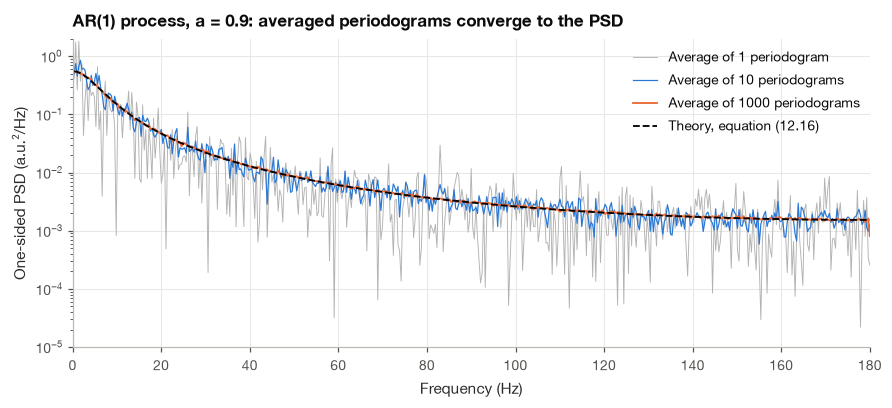

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for M, col, lw in [(1, "0.7", 0.6), (10, C[0], 0.8), (1000, C[1], 1.2)]:
    ax.semilogy(f_k[1:], pgrams[:M].mean(axis=0)[1:], color=col, lw=lw,
                label=f"Average of {M} periodogram{'s' if M > 1 else ''}")
ax.semilogy(f_k[1:], S_theory[1:], color="k", ls="--", lw=1.2, label="Theory, equation (12.16)")
ax.set(xlabel="Frequency (Hz)", ylabel="One-sided PSD (a.u.$^2$/Hz)", xlim=(0, 180), ylim=(1e-5, 2),
       title="AR(1) process, a = 0.9: averaged periodograms converge to the PSD")
ax.legend(loc="upper right")
plt.show()

The average sits on the theoretical curve at every number of realizations (the mean ratio is close to one), which confirms that $|X_N|^2/N$ is, apart from a small bias, the right quantity. What changes with averaging is the scatter: a single periodogram fluctuates around the truth with a standard deviation as large as the PSD itself, and averaging $M$ of them divides that by about $\sqrt{M}$. In practice we rarely have independent realizations, but we can cut one long recording into pieces and average those. That is the idea behind the Bartlett and Welch methods of the next section.

(sec-7-2-8)=
## 7.2.8 Application: How Much ECG Noise Can a Band-Pass Filter Remove?

The MIT-BIH Noise Stress Test Database {cite:p}`moody1984,goldberger2000` contains three 30-minute recordings of pure noise, made with ECG electrodes placed on active volunteers at sites where the ECG itself is barely visible: `bw` (baseline wander), `em` (electrode motion) and `ma` (muscle artifact). Because they are noise only, they are ideal for studying the PSD of real ECG contaminants. I use them here to answer a practical question with the tools of this section: if we pass each kind of noise through a 0.5–40 Hz band-pass filter, a typical setting for ECG monitoring, how much noise power remains?

### Step 1: Load five minutes of each noise record

In [10]:
fs = 360
noise = {}
for name in ["bw", "em", "ma"]:
    rec = wfdb.rdrecord(f"../data/nstdb/{name}", sampfrom=60 * fs, sampto=360 * fs, channels=[0])
    noise[name] = rec.p_signal[:, 0] - rec.p_signal[:, 0].mean()
    print(f"{name}: {noise[name].size / fs:.0f} s, RMS = {noise[name].std():.3f} mV")

bw: 300 s, RMS = 0.494 mV


em: 300 s, RMS = 0.603 mV
ma: 300 s, RMS = 0.205 mV


### Step 2: Estimate the PSDs

A single periodogram of five minutes of data would be as erratic as the gray curve in the last figure. We therefore average over 16 s segments using `scipy.signal.welch`, the estimator that [Section 7.3](03_nonparametric_psd.ipynb) derives in detail; here it is simply the practical version of the averaging we justified in [Section 7.2.7](#sec-7-2-7). Each segment has its linear trend removed, and the result is a one-sided PSD in mV²/Hz.

In [11]:
psd = {}
for name, x in noise.items():
    f_w, psd[name] = signal.welch(x, fs=fs, nperseg=16 * fs, detrend="linear")
print(f"Frequency resolution: {f_w[1]:.4f} Hz, {f_w.size} frequency bins from 0 to {f_w[-1]:.0f} Hz")

Frequency resolution: 0.0625 Hz, 2881 frequency bins from 0 to 180 Hz


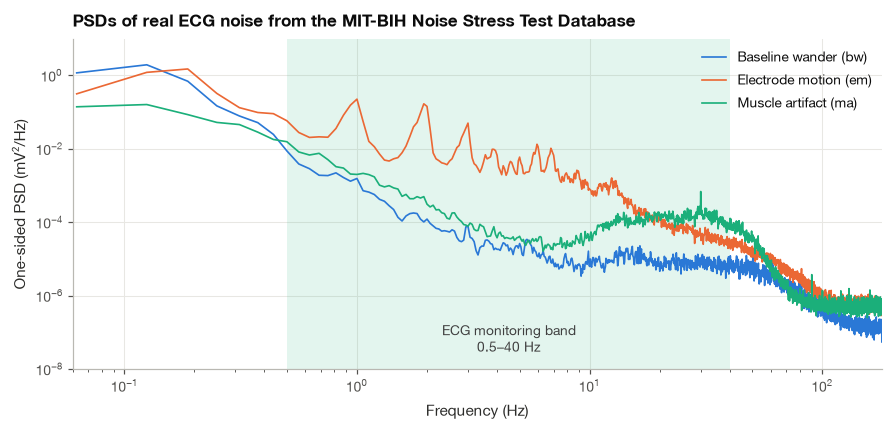

In [12]:
labels = {"bw": "Baseline wander (bw)", "em": "Electrode motion (em)", "ma": "Muscle artifact (ma)"}
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, name in enumerate(["bw", "em", "ma"]):
    ax.loglog(f_w[1:], psd[name][1:], color=C[i], lw=1.1, label=labels[name])
ax.axvspan(0.5, 40, color=C[2], alpha=0.12, lw=0)
ax.text(4.5, 3e-8, "ECG monitoring band\n0.5–40 Hz", ha="center", fontsize=9, color="0.25")
ax.set(xlabel="Frequency (Hz)", ylabel="One-sided PSD (mV$^2$/Hz)", xlim=(0.06, 180), ylim=(1e-8, 10),
       title="PSDs of real ECG noise from the MIT-BIH Noise Stress Test Database")
ax.legend(loc="upper right")
plt.show()

All three spectra fall steeply with frequency, so most of their power is at the low end. The baseline-wander record is the most extreme, dropping by about five orders of magnitude between 0.1 and 10 Hz. The electrode-motion record shows a train of peaks near 1, 2, 3 Hz and beyond, the harmonics of a roughly periodic movement of the electrodes, and it stays the largest of the three throughout the monitoring band. The muscle-artifact record has a broad hump between about 15 and 40 Hz and carries the most absolute power above 40 Hz, as expected from motor-unit activity.

### Step 3: Area equals power, band by band

By [(7.17)](#eq-7-17) the area under each one-sided PSD should equal the variance of the record, and partial areas give the power in each band. We integrate with the trapezoidal rule.

In [13]:
def band_power(f, S, f_lo, f_hi):
    """Integrate a one-sided PSD over f_lo <= f < f_hi (trapezoidal rule)."""
    m = (f >= f_lo) & (f <= f_hi)
    return np.trapezoid(S[m], f[m])


rows = []
for name, x in noise.items():
    S = psd[name]
    total = band_power(f_w, S, 0, fs / 2)
    rows.append({"record": name, "variance (mV^2)": x.var(), "PSD area (mV^2)": total,
                 "< 0.5 Hz (%)": 100 * band_power(f_w, S, 0, 0.5) / total,
                 "0.5-40 Hz (%)": 100 * band_power(f_w, S, 0.5, 40) / total,
                 "> 40 Hz (%)": 100 * band_power(f_w, S, 40, fs / 2) / total})
print(pd.DataFrame(rows).round(4).to_string(index=False))

record  variance (mV^2)  PSD area (mV^2)  < 0.5 Hz (%)  0.5-40 Hz (%)  > 40 Hz (%)
    bw           0.2443           0.2644       99.1511         0.7798       0.0691
    em           0.3632           0.3600       64.9586        34.8891       0.1522
    ma           0.0420           0.0437       79.3837        18.5899       2.0264


The PSD areas match the variances closely for `em` and `ma`. For `bw` the area is somewhat larger than the variance, and the reason is instructive: removing a linear trend from each 16 s segment and from the whole record are not the same operation for a signal whose power sits at periods of tens of seconds, so the two numbers measure slightly different things. The band fractions are the practically important result. For baseline wander, about 99% of the power lies below 0.5 Hz, so a high-pass filter can remove almost all of it. For electrode motion and muscle artifact, a third and a fifth of the power, respectively, lie inside the 0.5–40 Hz band, where the ECG itself lives.

### Step 4: Predict the filtered noise power with $S_y = |H|^2 S_x$

Equation [(7.20)](#eq-7-20) predicts the output PSD of any filter, and integrating it predicts the output power. We design a second-order Butterworth band-pass filter for 0.5–40 Hz (the design method belongs to Chapter 15; here we only need its frequency response), compute $|H(f)|^2$ on the Welch frequency grid, and compare the predicted output variance with the variance of the noise after actually filtering it.

In [14]:
sos = signal.butter(2, [0.5, 40], btype="bandpass", fs=fs, output="sos")
_, H = signal.sosfreqz(sos, worN=f_w, fs=fs)

rows = []
for name, x in noise.items():
    predicted = np.trapezoid(np.abs(H) ** 2 * psd[name], f_w)          # equation (12.20), integrated
    y = signal.sosfilt(sos, x)[20 * fs:]                                # drop the start-up transient
    rows.append({"record": name, "RMS before (mV)": x.std(), "predicted RMS after (mV)": np.sqrt(predicted),
                 "measured RMS after (mV)": y.std(), "power ratio pred/meas": predicted / y.var()})
print(pd.DataFrame(rows).round(3).to_string(index=False))

record  RMS before (mV)  predicted RMS after (mV)  measured RMS after (mV)  power ratio pred/meas
    bw            0.494                     0.075                    0.072                  1.082
    em            0.603                     0.360                    0.371                  0.941
    ma            0.205                     0.094                    0.094                  0.993


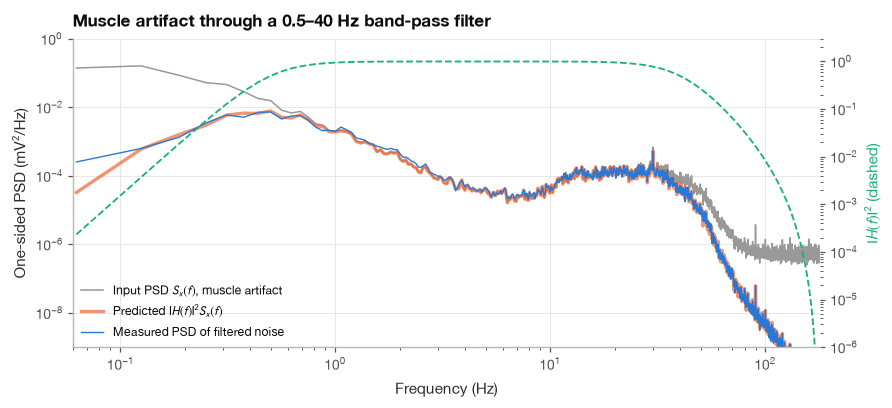

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.6))
y_ma = signal.sosfilt(sos, noise["ma"])[20 * fs:]
f_y, S_y_meas = signal.welch(y_ma, fs=fs, nperseg=16 * fs, detrend="linear")
ax.loglog(f_w[1:], psd["ma"][1:], color="0.6", lw=1, label="Input PSD $S_x(f)$, muscle artifact")
ax.loglog(f_w[1:], (np.abs(H) ** 2 * psd["ma"])[1:], color=C[1], lw=2.2, alpha=0.7,
          label=r"Predicted $|H(f)|^2 S_x(f)$")
ax.loglog(f_y[1:], S_y_meas[1:], color=C[0], lw=0.9, label="Measured PSD of filtered noise")
ax2 = ax.twinx()
ax2.loglog(f_w[1:], np.abs(H[1:]) ** 2, color=C[2], ls="--", lw=1.2)
ax2.set_ylabel(r"$|H(f)|^2$ (dashed)", color=C[2])
ax2.set_ylim(1e-6, 3)
ax2.grid(False)
ax.set(xlabel="Frequency (Hz)", ylabel="One-sided PSD (mV$^2$/Hz)", xlim=(0.06, 180), ylim=(1e-9, 1),
       title="Muscle artifact through a 0.5–40 Hz band-pass filter")
ax.legend(loc="lower left", fontsize=8)
plt.show()

For the muscle-artifact record the predicted power is within 1% of the measured value, and for electrode motion within about 6%, which is about as well as a spectral estimate from five minutes of nonstationary data can do. For baseline wander the agreement is looser (the power after filtering is tiny and comes from the steep skirt of the filter at 0.5 Hz, exactly where a PSD estimate with 0.0625 Hz resolution is least precise), but the conclusion is the same in all three cases.

### Step 5: Interpret

The band-pass filter removes nearly all of the baseline wander, cuts the electrode-motion noise to roughly 60% of its RMS value and the muscle artifact to under half. What remains is the noise that shares the ECG's own frequency band, and *no* linear time-invariant filter can remove it without also removing ECG, because by [(7.20)](#eq-7-20) the filter can only scale each frequency, not tell signal from noise within it. This is the quantitative reason that electrode-motion artifact is regarded as the hardest ECG contaminant, and it motivates the methods of [Chapter 10](../ch16_noise_removal/index.md), which exploit more than the spectrum: repetition of the beat (signal averaging), the statistics of signal and noise together (the Wiener filter of [Section 10.2](../ch16_noise_removal/02_wiener_filter.ipynb)) or a reference noise channel (adaptive filters). The practical cleaning of real ECG is taken up step by step in [Chapter 12](../ch18_ecg_preprocessing/index.md).

## Summary

A realization of a stationary random process has infinite energy and no ordinary Fourier transform, but its average power can still be distributed over frequency. The power spectral density is defined as the limit of $\mathbb{E}\{|X_N|^2\}/N$, and the Wiener–Khinchin theorem, derived by grouping the double sum by lag, shows that it equals the Fourier transform of the autocorrelation function. The PSD is real, even and non-negative, and its area is the mean power; in hertz it is measured in units such as µV²/Hz or mV²/Hz, usually in one-sided form. White noise has a flat PSD; the AR(1) process has the closed-form spectrum [(7.16)](#eq-7-16), which we derived twice, once from its autocorrelation and once from the rule $S_y = |H|^2 S_x$ for random signals through LTI systems. Averaging periodograms over realizations converged to the theory, and on real ECG noise the PSD predicted, to within a few percent in RMS, how much muscle and electrode-motion noise survives a 0.5–40 Hz filter.

The finite-length formula [(7.13)](#eq-7-13) already contains the two problems that define practical spectral estimation: the triangular weighting blurs the spectrum (bias), and a single realization scatters wildly around its expectation (variance). [Section 7.3](03_nonparametric_psd.ipynb) quantifies both and develops the Bartlett and Welch estimators that every EEG and HRV toolbox uses, and [Section 7.4](04_parametric_psd.ipynb) turns the "white noise through a filter" view into a parametric estimator.

## Exercises

1. Show directly from [(7.14)](#eq-7-14) that a WSS process with $R_x[k] = \sigma^2\big(\delta[k] + \tfrac{1}{2}\delta[k-1] + \tfrac{1}{2}\delta[k+1]\big)$ has PSD $\sigma^2(1 + \cos\Omega)$. Is it non-negative for all $\Omega$? What happens if the coefficients $\tfrac{1}{2}$ are replaced by $0.8$, and what does that tell you about which sequences can be autocorrelations?
2. White noise with $\sigma_w = 10$ µV, sampled at $f_s = 160$ Hz, is the background of an EEG model. Compute its two-sided and one-sided PSD in µV²/Hz and the power in the alpha band (8–13 Hz). Check your answer by integrating a `scipy.signal.welch` estimate of simulated noise.
3. The three-point moving average $y[n] = \tfrac{1}{3}(x[n] + x[n-1] + x[n-2])$ is driven by white noise of variance $\sigma_w^2$. Use [(7.20)](#eq-7-20) to find $S_y(e^{j\Omega})$ and [(7.21)](#eq-7-21) to find $\sigma_y^2$. Verify both by simulation.
4. Repeat the derivation of Example 7.2.1 for the process $x[n] = w[n] + b\,w[n-1]$ (a first-order moving-average process). Find $R_x[k]$ first, then $S_x$ via [(7.14)](#eq-7-14), and finally confirm the result with [(7.20)](#eq-7-20).
5. Using equation [(7.13)](#eq-7-13), plot the expected periodogram of the AR(1) process with $a = 0.9$ for $N = 16, 64, 256$ together with the true PSD. At which frequencies is the bias largest, and why?
6. (Applied.) Repeat Steps 3–5 of [Section 7.2.8](#sec-7-2-8) with a 0.67–150 Hz band-pass filter, close to the diagnostic bandwidth recommended for clinical 12-lead ECGs {cite:p}`kligfield2007`. How much more electrode-motion and muscle noise passes? Express the result as an SNR change in dB for a 1 mV QRS complex.

## Further Reading

The Wiener–Khinchin theorem and the PSD of filtered processes are treated rigorously in {cite:t}`papoulis2002` (Chapters 6 and 12), including the continuous-time case and conditions weaker than absolute summability. {cite:t}`stoica2005` (Chapter 1) gives a compact discrete-time development very close to the one here, and {cite:t}`bendat2010` is the best source on one-sided spectra, units and practical measurement conventions. The noise records used in [Section 7.2.8](#sec-7-2-8) are described by {cite:t}`moody1984`.